# NYC Taxi Demand Analysis and Forecasting

## Goal
The goal of this project is to analyze NYC yellow taxi trip data, identify demand patterns over time, and build a simple model to forecast hourly trip demand.

## Learning goals
- practice working with real transportation data
- learn time-based feature engineering
- aggregate event data into a time series
- build and evaluate a basic forecasting model

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

In [4]:
file_path = "yellow_tripdata_2025-01.parquet"
df = pd.read_parquet(file_path)

df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0


In [5]:
df.shape

(3475226, 20)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3475226 entries, 0 to 3475225
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

In [7]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'Airport_fee',
 'cbd_congestion_fee']

In [8]:
df.isnull().sum().sort_values(ascending=False)

passenger_count          540149
congestion_surcharge     540149
store_and_fwd_flag       540149
RatecodeID               540149
Airport_fee              540149
tpep_dropoff_datetime         0
VendorID                      0
tpep_pickup_datetime          0
DOLocationID                  0
payment_type                  0
trip_distance                 0
PULocationID                  0
extra                         0
fare_amount                   0
mta_tax                       0
tip_amount                    0
improvement_surcharge         0
tolls_amount                  0
total_amount                  0
cbd_congestion_fee            0
dtype: int64

## Initial observations
- The dataset is trip-level data, so each row is one taxi trip.
- Pickup and dropoff datetime columns will be central to this project.
- We will need to clean invalid trips before doing analysis or forecasting.

In [9]:
df_clean = df.copy()

In [10]:
df_clean["tpep_pickup_datetime"] = pd.to_datetime(df_clean["tpep_pickup_datetime"])
df_clean["tpep_dropoff_datetime"] = pd.to_datetime(df_clean["tpep_dropoff_datetime"])

In [11]:
df_clean = df_clean.dropna(subset=["tpep_pickup_datetime", "tpep_dropoff_datetime"]).copy()

In [12]:
df_clean["trip_duration_minutes"] = (
    df_clean["tpep_dropoff_datetime"] - df_clean["tpep_pickup_datetime"]
).dt.total_seconds() / 60

In [13]:
df_clean = df_clean[df_clean["trip_duration_minutes"] > 0].copy()

In [14]:
df_clean = df_clean[df_clean["trip_duration_minutes"] <= 360].copy()

In [15]:
df_clean = df_clean[df_clean["trip_distance"] >= 0].copy()
df_clean = df_clean[df_clean["total_amount"] >= 0].copy()

In [16]:
df_clean = df_clean.drop_duplicates().copy()

In [17]:
df_clean.shape

(3408951, 21)

In [18]:
df_clean["pickup_hour"] = df_clean["tpep_pickup_datetime"].dt.hour
df_clean["pickup_dayofweek"] = df_clean["tpep_pickup_datetime"].dt.dayofweek
df_clean["pickup_date"] = df_clean["tpep_pickup_datetime"].dt.date

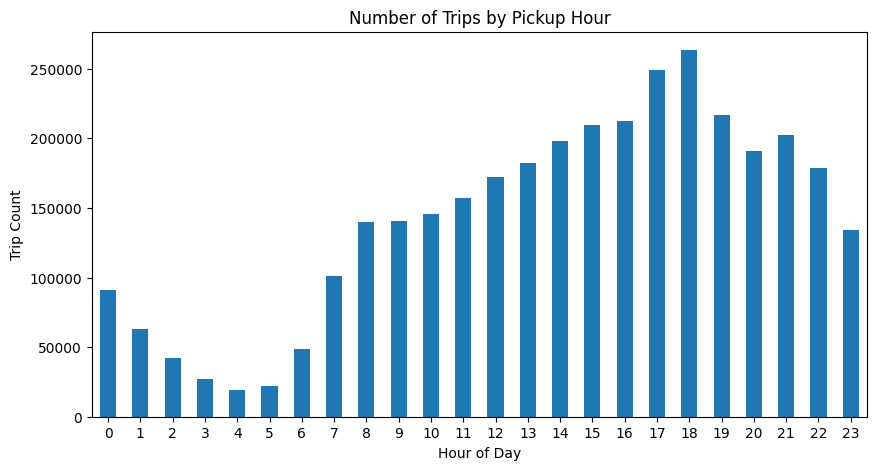

In [19]:
hourly_counts = df_clean["pickup_hour"].value_counts().sort_index()

hourly_counts.plot(kind="bar", figsize=(10, 5))
plt.title("Number of Trips by Pickup Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Trip Count")
plt.xticks(rotation=0)
plt.show()

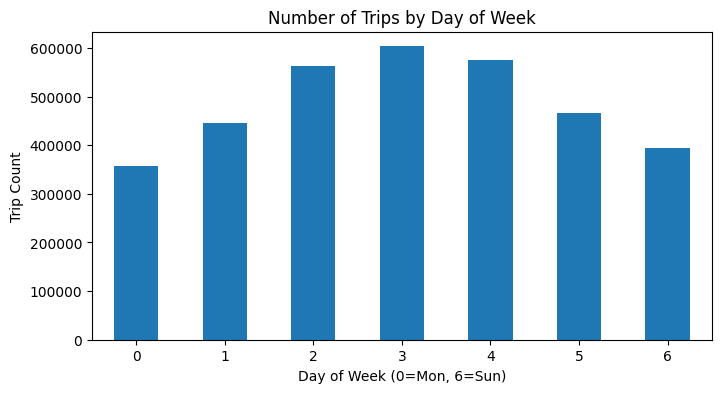

In [20]:
weekday_counts = df_clean["pickup_dayofweek"].value_counts().sort_index()

weekday_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Number of Trips by Day of Week")
plt.xlabel("Day of Week (0=Mon, 6=Sun)")
plt.ylabel("Trip Count")
plt.xticks(rotation=0)
plt.show()

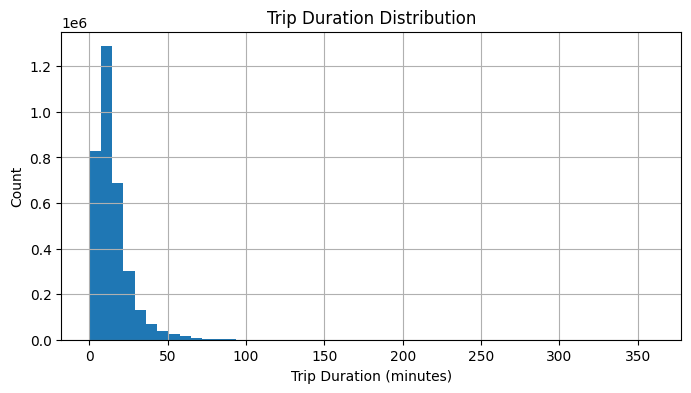

In [21]:
df_clean["trip_duration_minutes"].hist(figsize=(8, 4), bins=50)
plt.title("Trip Duration Distribution")
plt.xlabel("Trip Duration (minutes)")
plt.ylabel("Count")
plt.show()

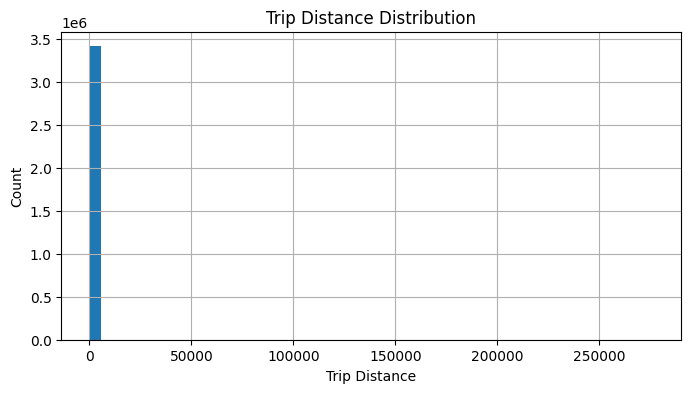

In [22]:
df_clean["trip_distance"].hist(figsize=(8, 4), bins=50)
plt.title("Trip Distance Distribution")
plt.xlabel("Trip Distance")
plt.ylabel("Count")
plt.show()

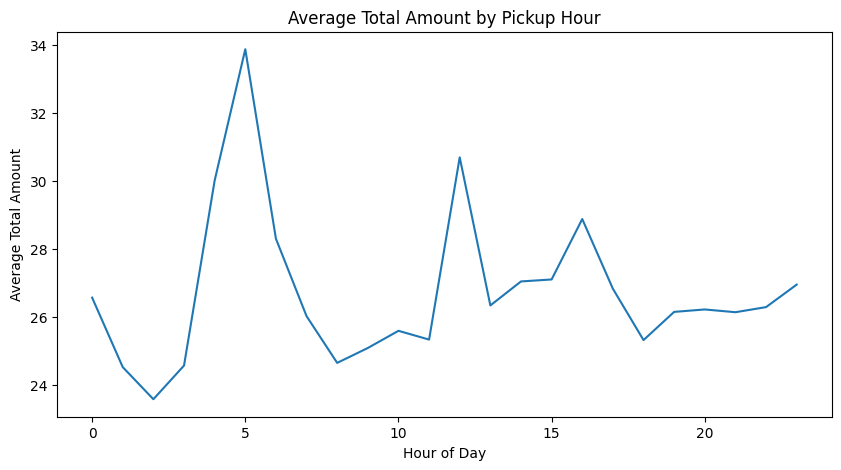

In [23]:
avg_revenue_by_hour = df_clean.groupby("pickup_hour")["total_amount"].mean()

avg_revenue_by_hour.plot(figsize=(10, 5))
plt.title("Average Total Amount by Pickup Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Total Amount")
plt.show()

In [24]:
hourly_demand = (
    df_clean.set_index("tpep_pickup_datetime")
    .resample("h")
    .size()
    .rename("trip_count")
    .to_frame()
)

In [25]:
hourly_demand.head()

,trip_count
tpep_pickup_datetime,
2024-12-31 20:00:00,3
2024-12-31 21:00:00,3
2024-12-31 22:00:00,0
2024-12-31 23:00:00,15
2025-01-01 00:00:00,6996


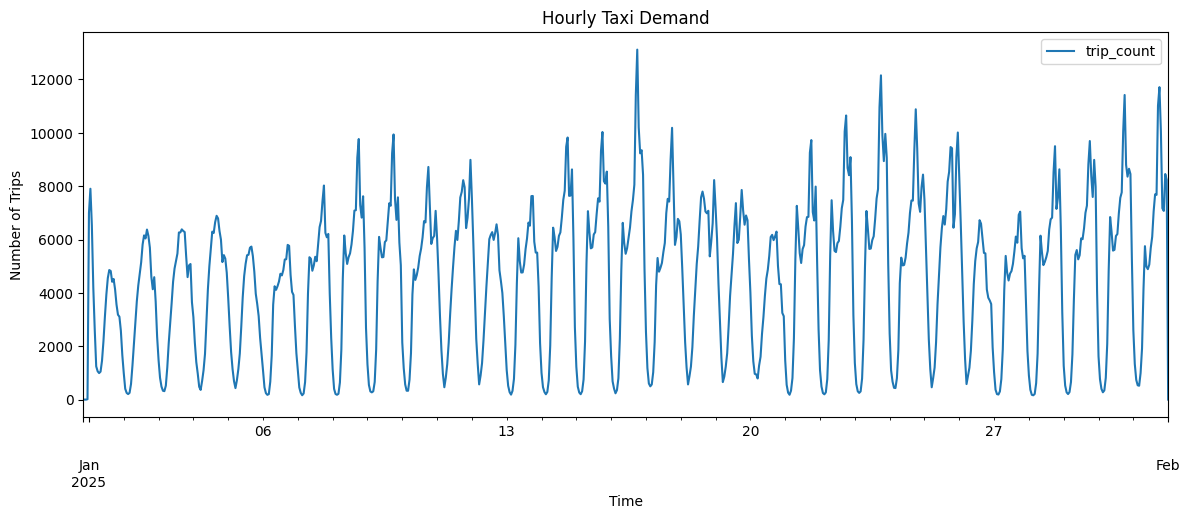

In [26]:
hourly_demand.plot(figsize=(14, 5))
plt.title("Hourly Taxi Demand")
plt.xlabel("Time")
plt.ylabel("Number of Trips")
plt.show()

## This is one of the biggest conceptual shifts in the project:
We have
- converted raw data into trip rows,
- converted forecasting data into hourly counts.

## We are doing forecasting, and our target is:
- trip_count at hour t

We are going to predict it using information from earlier hours.

In [27]:
# Start from the hourly demand series
ts = hourly_demand.copy()

# LAG FEATURES
ts["lag_1"] = ts["trip_count"].shift(1)
ts["lag_2"] = ts["trip_count"].shift(2)
ts["lag_3"] = ts["trip_count"].shift(3)
ts["lag_6"] = ts["trip_count"].shift(6)
ts["lag_12"] = ts["trip_count"].shift(12)
ts["lag_24"] = ts["trip_count"].shift(24)
ts["lag_48"] = ts["trip_count"].shift(48)
ts["lag_168"] = ts["trip_count"].shift(168)   # same hour one week ago

# ROLLING FEATURES
# shift(1) is important so you only use past information
ts["rolling_mean_6"] = ts["trip_count"].shift(1).rolling(6).mean()
ts["rolling_mean_24"] = ts["trip_count"].shift(1).rolling(24).mean()
ts["rolling_mean_168"] = ts["trip_count"].shift(1).rolling(168).mean()

ts["rolling_std_6"] = ts["trip_count"].shift(1).rolling(6).std()
ts["rolling_std_24"] = ts["trip_count"].shift(1).rolling(24).std()

# OPTIONAL "CHANGE" FEATURES
ts["diff_1"] = ts["trip_count"].shift(1) - ts["trip_count"].shift(2)
ts["diff_24"] = ts["trip_count"].shift(1) - ts["trip_count"].shift(25)

# CALENDAR FEATURES
ts["is_weekend"] = (ts.index.dayofweek >= 5).astype(int)

# CYCLICAL TIME FEATURES
ts["hour_sin"] = np.sin(2 * np.pi * ts.index.hour / 24)
ts["hour_cos"] = np.cos(2 * np.pi * ts.index.hour / 24)

ts["dow_sin"] = np.sin(2 * np.pi * ts.index.dayofweek / 7)
ts["dow_cos"] = np.cos(2 * np.pi * ts.index.dayofweek / 7)

In [29]:
# Drop rows with NaNs created by lag/rolling features
ts = ts.dropna().copy()

In [30]:
feature_cols = [
    "lag_1", "lag_2", "lag_3", "lag_6", "lag_12", "lag_24", "lag_48", "lag_168",
    "rolling_mean_6", "rolling_mean_24", "rolling_mean_168",
    "rolling_std_6", "rolling_std_24",
    "diff_1", "diff_24",
    "is_weekend",
    "hour_sin", "hour_cos",
    "dow_sin", "dow_cos"
]

X = ts[feature_cols]
y = ts["trip_count"]

In [31]:
split_idx = int(len(ts) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

In [32]:
baseline_pred = X_test["lag_1"]

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = root_mean_squared_error(y_test, baseline_pred)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 983.1623931623932
Baseline RMSE: 1477.3169315483108


In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = root_mean_squared_error(y_test, lr_pred)

print("Linear Regression MAE:", lr_mae)
print("Linear Regression RMSE:", lr_rmse)

Linear Regression MAE: 473.3476496667161
Linear Regression RMSE: 828.2939701080428


In [34]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb = HistGradientBoostingRegressor(random_state=42)
hgb.fit(X_train, y_train)

hgb_pred = hgb.predict(X_test)

hgb_mae = mean_absolute_error(y_test, hgb_pred)
hgb_rmse = root_mean_squared_error(y_test, hgb_pred)

print("HistGradientBoostingRegressor MAE:", hgb_mae)
print("HistGradientBoostingRegressor RMSE:", hgb_rmse)

HistGradientBoostingRegressor MAE: 410.05465930693094
HistGradientBoostingRegressor RMSE: 832.8484147472753


In [35]:
results = pd.DataFrame({
    "Model": ["Naive Baseline", "Linear Regression", "HistGradientBoostingRegressor"],
    "MAE": [baseline_mae, lr_mae, hgb_mae],
    "RMSE": [baseline_rmse, lr_rmse, hgb_rmse]
})

results

,Model,MAE,RMSE
0,Naive Baseline,983.162393,1477.316932
1,Linear Regression,473.347650,828.293970
2,HistGradientBoostingRegressor,410.054659,832.848415


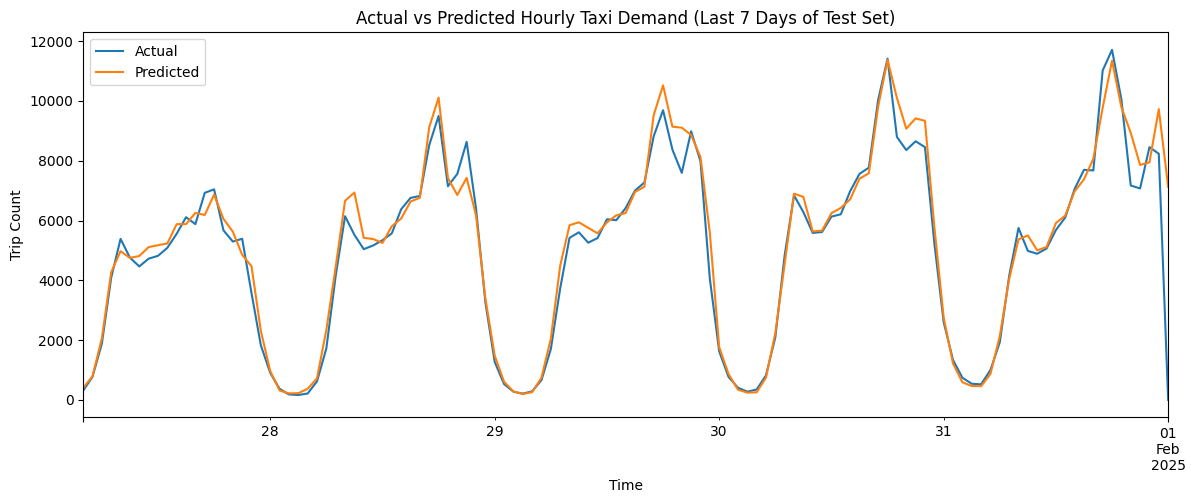

In [38]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": hgb_pred
}, index=y_test.index)

comparison.tail(168).plot(figsize=(14, 5))
plt.title("Actual vs Predicted Hourly Taxi Demand (Last 7 Days of Test Set)")
plt.xlabel("Time")
plt.ylabel("Trip Count")
plt.show()

In [43]:
coef_df = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": lr.coef_
}).sort_values("Coefficient")

coef_df

,Feature,Coefficient
17,hour_cos,-416.805325
19,dow_cos,-304.598077
16,hour_sin,-88.532912
18,dow_sin,-32.421606
9,rolling_mean_24,-0.956106
8,rolling_mean_6,-0.229551
11,rolling_std_6,-0.187353
1,lag_2,-0.065161
6,lag_48,-0.042258
4,lag_12,0.069100


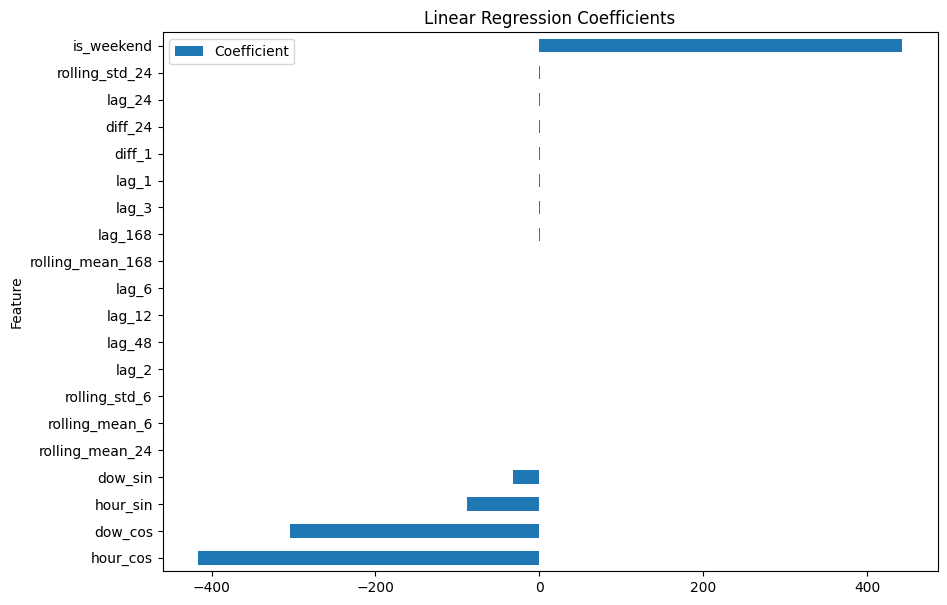

In [46]:
coef_df.plot(kind="barh", x="Feature", y="Coefficient", figsize=(10, 7))
plt.title("Linear Regression Coefficients")
plt.show()

In [47]:
hourly_demand.to_csv("hourly_demand.csv")
results.to_csv("model_results.csv", index=False)
comparison.to_csv("actual_vs_predicted.csv")

## Conclusion

This project analyzed NYC yellow taxi trip data and converted trip-level records into an hourly demand time series.

### Main steps
- loaded one month of real taxi trip data
- cleaned invalid trips
- engineered time-based features
- aggregated the data into hourly trip counts
- created lag features for forecasting
- compared a naive baseline with linear regression and hist gradient boosting regressor
- evaluated results using MAE and RMSE

### Main findings
- taxi demand followed strong hourly and weekly patterns
- lagged demand values were useful predictors
- the forecasting model could be compared against a simple previous-hour baseline
- time-aware splitting was necessary to evaluate future prediction honestly